# 🌌 APP — Detecção de EPBs

Carrega automaticamente a versão mais recente do modelo treinado e 
processa as imagens do diretório `img-teste/`.

**Funcionalidades:**
1. Predição (EPB / Sem EPB) com indicador de confiança
2. Análise detalhada de features (mapa de importância)
3. Análise SHAP (contribuição real de cada região)
4. Análise temporal de sequência de imagens

In [1]:
from PIL import Image
import numpy as np
from pathlib import Path

from epb_detection_system import (
    preprocess_epb_image,
    load_model,
    load_epb_dataset,
    explain_feature_importance_3 as explain_features,
    explain_shap_importance,
    analyze_temporal_sequence,
    analyze_critical_periods,
)

In [2]:
# ========== CARREGAMENTO DO MODELO (auto-detecta a versão mais recente) ==========
MODEL_DIR = Path('models')
MODEL_PREFIX = 'epb_recognition_model-v'
MODEL_SUFFIX = '.pkl'

# Encontra todos os modelos disponíveis e ordena pela versão
model_files = sorted(
    MODEL_DIR.glob(f'{MODEL_PREFIX}*{MODEL_SUFFIX}'),
    key=lambda p: [int(x) for x in p.stem.replace(MODEL_PREFIX, '').split('.')],
    reverse=True,
)

if not model_files:
    raise FileNotFoundError(
        f"Nenhum modelo encontrado em '{MODEL_DIR}'. "
        "Execute o notebook de treinamento primeiro."
    )

model_path = model_files[0]  # versão mais recente
print(f"📦 Carregando modelo: {model_path.name}")

model_data = load_model(str(model_path))
system = model_data.system
target_size = model_data.target_size

print(f"   ✓ Versão: v{model_data.version}")
print(f"   ✓ Tamanho das imagens: {target_size}")
if model_data.test_metrics:
    acc = model_data.test_metrics.get('accuracy', 0)
    print(f"   ✓ Accuracy (teste): {acc:.2%}")
print("   ✓ Modelo carregado com sucesso!")

📦 Carregando modelo: epb_recognition_model-v3.0.pkl
   ✓ Versão: v3.0
   ✓ Tamanho das imagens: (64, 64)
   ✓ Accuracy (teste): 100.00%
   ✓ Modelo carregado com sucesso!


In [3]:
# ========== HELPER: carrega e pré-processa imagens de img-teste ==========
IMG_FOLDER = Path('img-teste')

def load_test_images(folder=IMG_FOLDER):
    """Retorna lista de (path, imagem_processada) para cada imagem na pasta."""
    files = sorted(
        list(folder.glob('*.png')) +
        list(folder.glob('*.jpg')) +
        list(folder.glob('*.jpeg'))
    )
    if not files:
        print(f"⚠️  Nenhuma imagem encontrada em '{folder}'")
    return files

def process_image(img_path):
    """Carrega, redimensiona e pré-processa uma imagem."""
    img = Image.open(img_path).convert('L')
    img = np.array(img.resize(target_size))
    return preprocess_epb_image(img)

In [4]:
# ========== 1. PREDIÇÕES ==========
image_files = load_test_images()

if image_files:
    print("="*70)
    print(f"🔍 PREDIÇÕES PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")

    for img_path in image_files:
        try:
            img = process_image(img_path)
            prob = system.predict_proba(img.reshape(1, *img.shape))[0]
            pred = np.argmax(prob)
            confidence = max(prob)

            print(f"📸 {img_path.name}")
            print(f"   EPB detectada: {'SIM' if pred == 1 else 'NÃO'}")
            print(f"   Probabilidade: {prob[1]*100:.2f}%")

            if confidence > 0.9:
                print(f"   Confiança: 🟢 ALTA ({confidence*100:.1f}%)")
            elif confidence > 0.7:
                print(f"   Confiança: 🟡 MÉDIA ({confidence*100:.1f}%)")
            else:
                print(f"   Confiança: 🔴 BAIXA ({confidence*100:.1f}%)")
            print()

        except Exception as e:
            print(f"❌ {img_path.name}: {e}\n")

    print("="*70)
    print("✅ PROCESSAMENTO CONCLUÍDO")
    print("="*70)

🔍 PREDIÇÕES PARA 2 IMAGENS

📸 O6_BJL_20250723_003008.png
   EPB detectada: NÃO
   Probabilidade: 2.37%
   Confiança: 🟢 ALTA (97.6%)

📸 O6_CA_20251023_001620.png
   EPB detectada: SIM
   Probabilidade: 97.42%
   Confiança: 🟢 ALTA (97.4%)

✅ PROCESSAMENTO CONCLUÍDO


🔬 ANÁLISE DETALHADA DE FEATURES PARA 2 IMAGENS



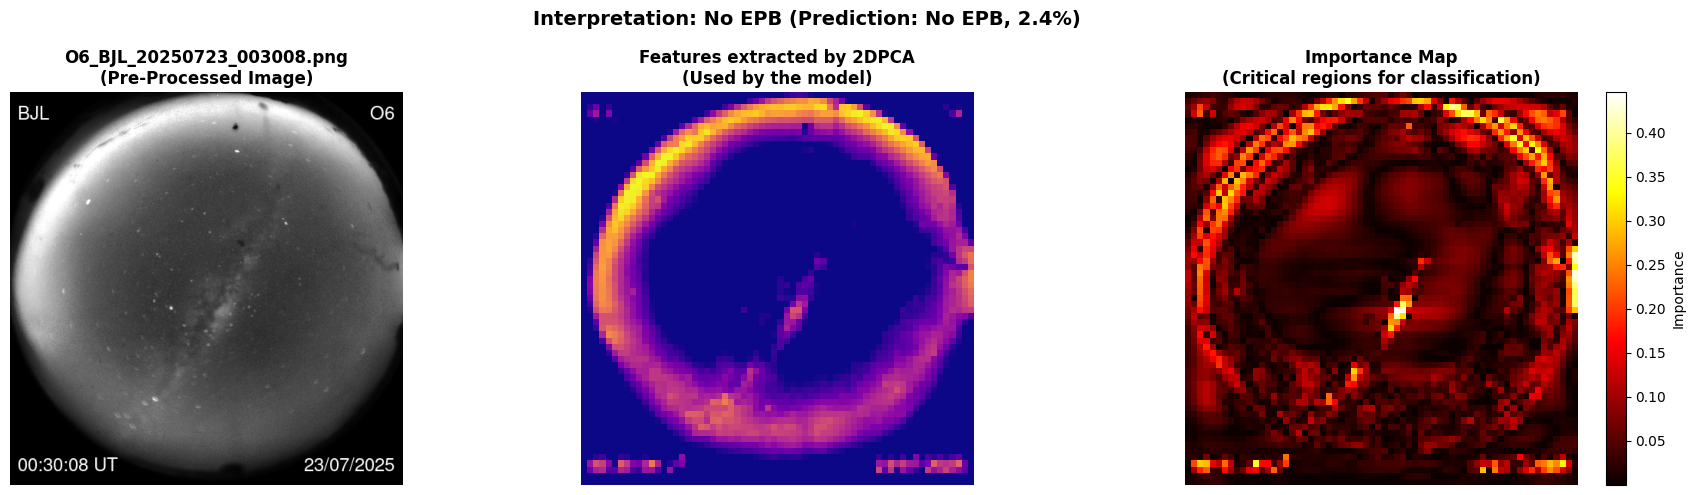

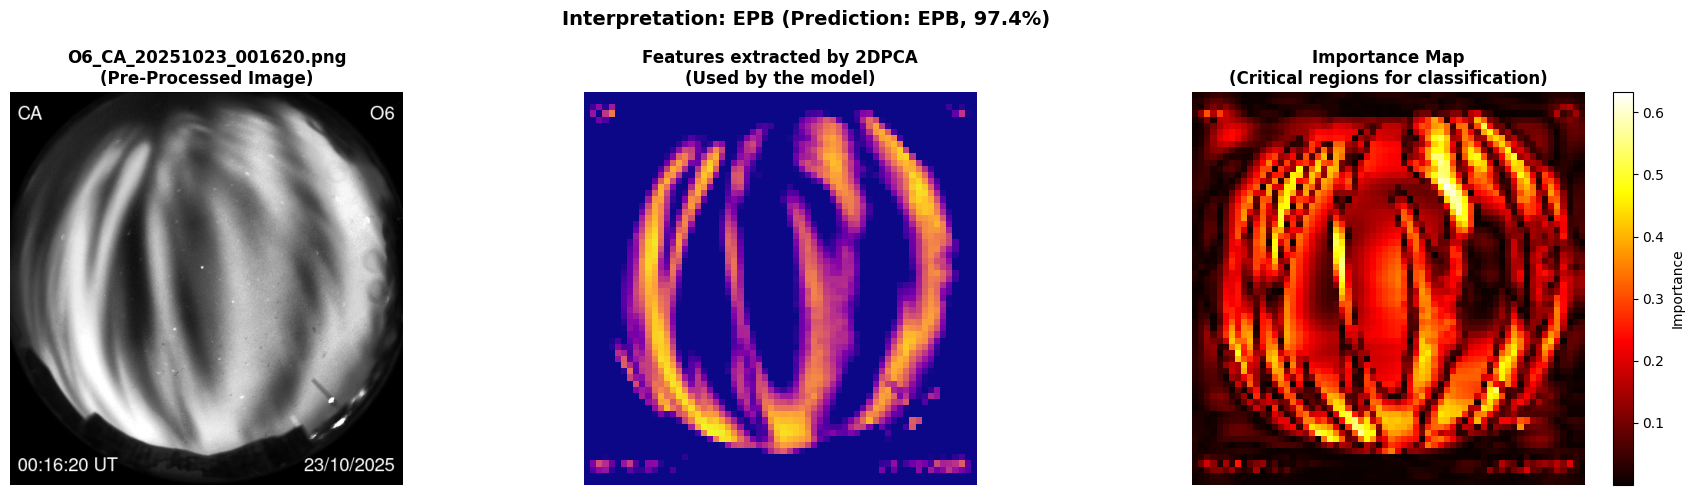

In [5]:
# ========== 2. ANÁLISE DETALHADA DE FEATURES ==========
image_files = load_test_images()

if image_files:
    print("="*70)
    print(f"🔬 ANÁLISE DETALHADA DE FEATURES PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")

    for img_path in image_files:
        try:
            img = process_image(img_path)
            pred = system.predict(img.reshape(1, *img.shape))[0]

            explain_features(
                system=system,
                X_sample=img,
                y_sample=pred,
                filename=img_path.name,
            )
        except Exception as e:
            print(f"❌ Erro ao analisar {img_path.name}: {e}\n")

📦 Carregando imagens de background para análise SHAP...


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
TreeExplainer falhou com xgboost, tentando próximo modelo...


   ✓ 100 imagens de background carregadas

🔬 ANÁLISE SHAP PARA 2 IMAGENS


🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_003008.png
   • True class: No EPB
   • Prediction: No EPB (2.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 44.3% (↓ No EPB)
   • Upper Right: 36.1% (↓ No EPB)
   • Lower Left: 10.3% (↓ No EPB)
   • Lower Right: 9.2% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.132 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2767: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2767: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


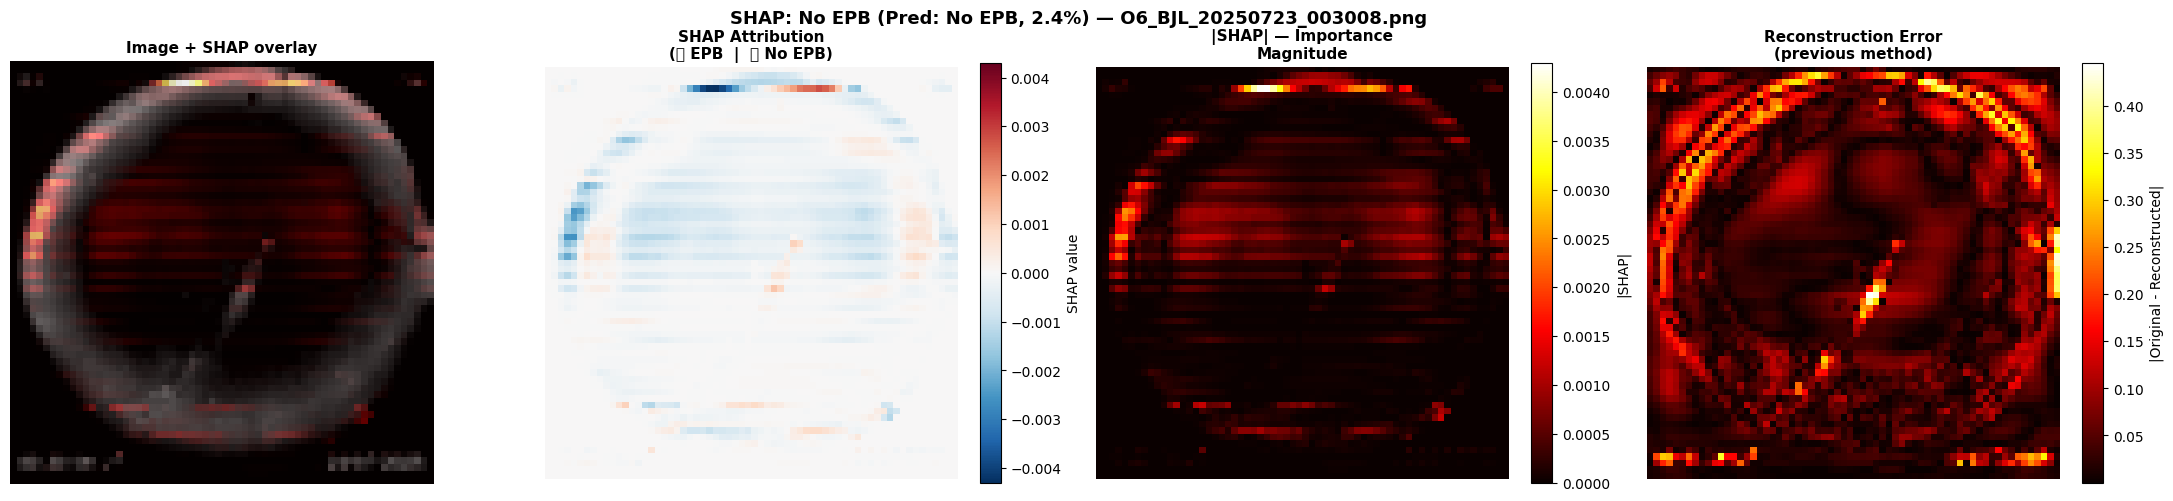

TreeExplainer falhou com xgboost, tentando próximo modelo...
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2767: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2767: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251023_001620.png
   • True class: EPB
   • Prediction: EPB (97.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 41.7% (↑ EPB)
   • Upper Right: 35.9% (↑ EPB)
   • Lower Right: 12.3% (↑ EPB)
   • Lower Left: 10.1% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.525 (Spearman)
   → Correlação moderada: SHAP revela regiões adicionais

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


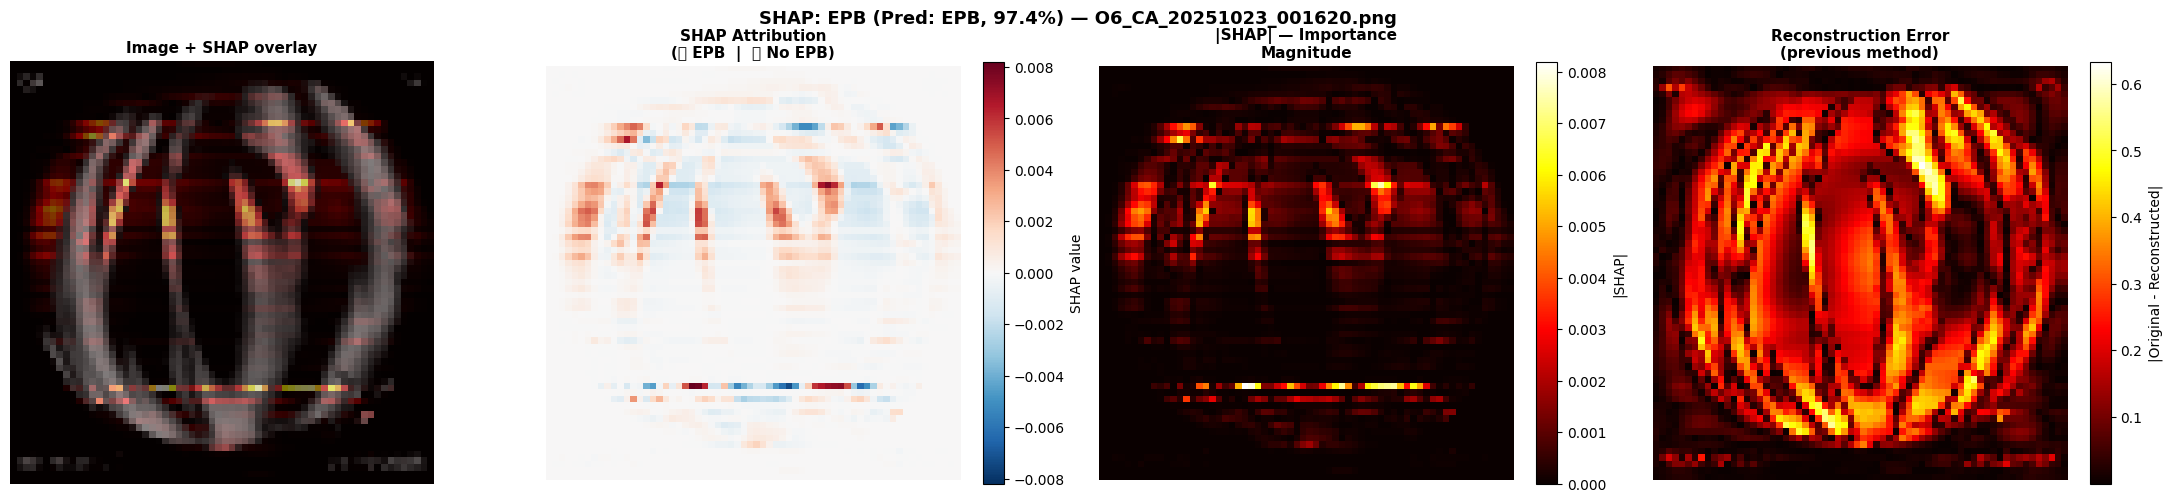

In [6]:
# ========== 3. ANÁLISE SHAP ==========
# Carrega subconjunto de imagens como background para SHAP
print("📦 Carregando imagens de background para análise SHAP...")
X_bg, _, _ = load_epb_dataset(
    data_folder='data/all-images',
    label_file='data/epb_labels.csv',
    target_size=target_size,
    apply_preprocessing=True,
)
if len(X_bg) > 100:
    X_bg = X_bg[np.random.RandomState(42).choice(len(X_bg), 100, replace=False)]
print(f"   ✓ {len(X_bg)} imagens de background carregadas\n")

image_files = load_test_images()

if image_files:
    print("="*70)
    print(f"🔬 ANÁLISE SHAP PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")

    for img_path in image_files:
        try:
            img = process_image(img_path)
            pred = system.predict(img.reshape(1, *img.shape))[0]

            explain_shap_importance(
                system=system,
                X_sample=img,
                y_sample=pred,
                X_background=X_bg,
                filename=img_path.name,
                method='tree',
            )
        except Exception as e:
            print(f"❌ Erro ao analisar {img_path.name}: {e}\n")

## 🕐 Análise Temporal de Sequência de Imagens

Analisa como a probabilidade de EPB evolui ao longo de uma noite de observação.
Útil para verificar se o modelo detecta EPBs **antes** de serem visíveis ao olho humano.

📂 Pastas disponíveis para análise temporal:
   0: util/BJL_20250722/processed  (230 imagens)
   1: util/CA_20250407/processed  (57 imagens)
   2: util/CA_20251022/processed  (140 imagens)
   3: util/CA_20251027/processed  (103 imagens)
   4: util/CA_20251218/processed  (136 imagens)
   5: util/CP_20240209/processed  (123 imagens)
   6: util/STR_20231112/processed  (135 imagens)

🔍 Selecionada: util/CA_20251022/processed

🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES
📂 Folder: util/CA_20251022/processed
📸 Total images: 140

📊 Prediction summary:
   • With EPB: 140 images (100.0%)
   • No EPB: 0 images (0.0%)
   • Average EPB probability: 91.5%
   • Maximum EPB probability: 97.4%
   • Minimum EPB probability: 57.3%


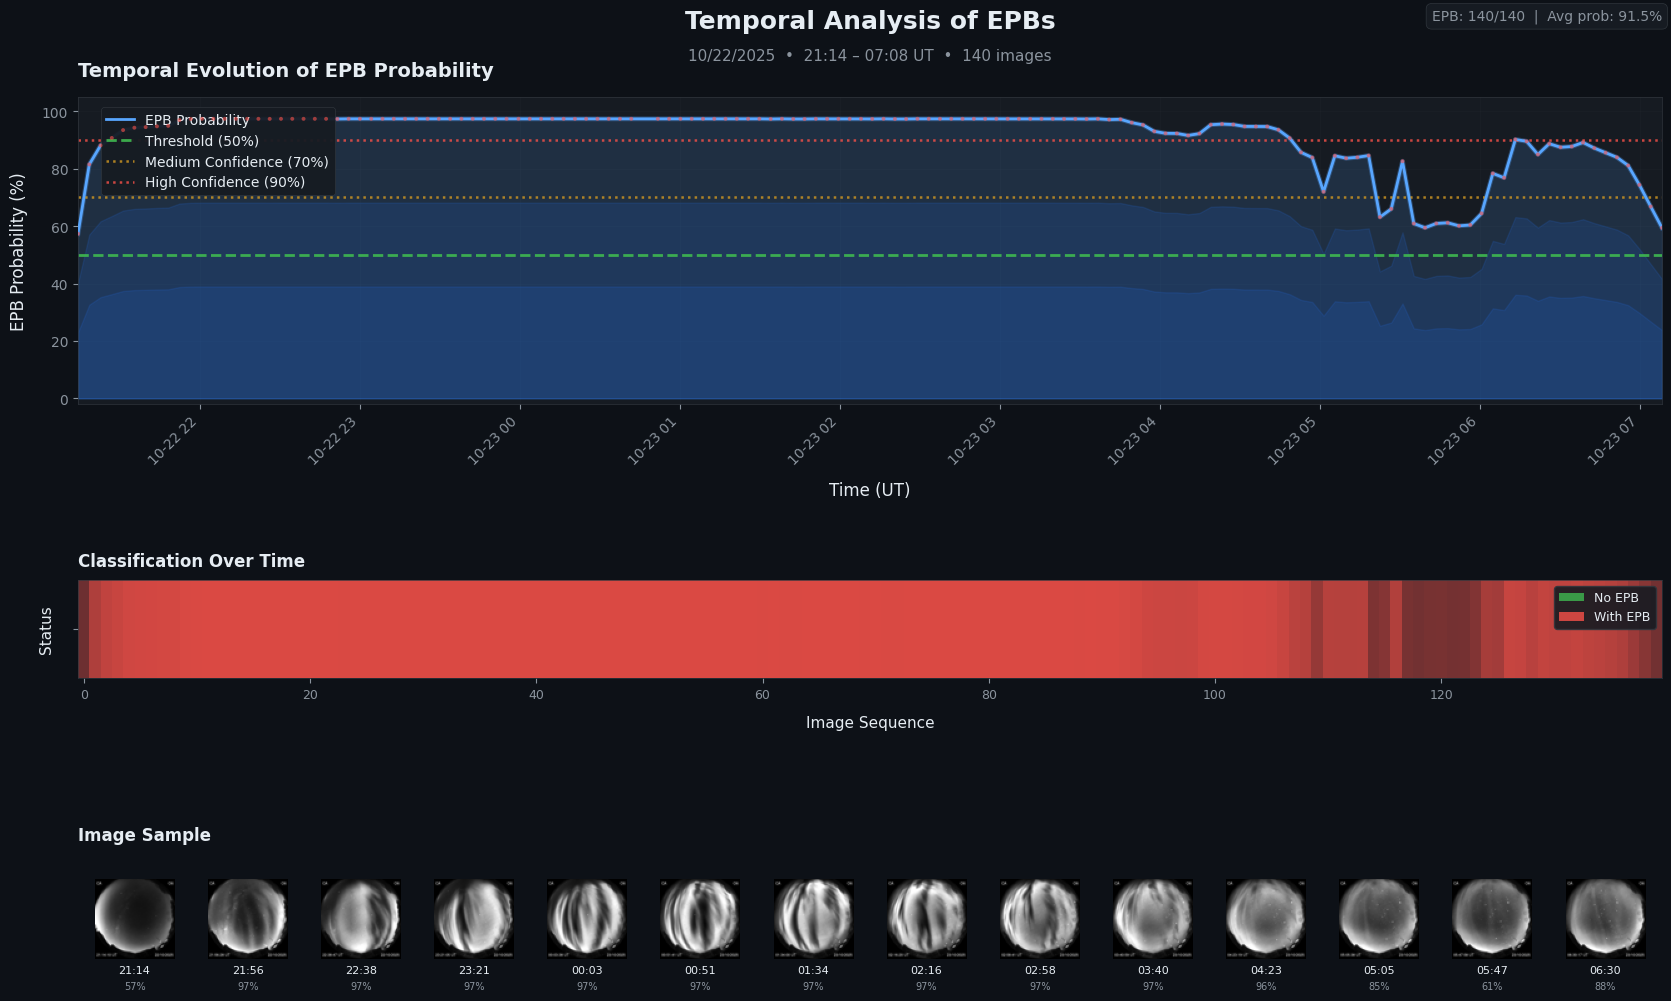


✅ TEMPORAL ANALYSIS COMPLETED


In [7]:
# ========== 4. ANÁLISE TEMPORAL ==========
# Lista as pastas disponíveis em util/*/processed
available_folders = sorted(Path('util').glob('*/processed'))

print("📂 Pastas disponíveis para análise temporal:")
for i, folder in enumerate(available_folders):
    n_imgs = len(list(folder.glob('*.png')))
    print(f"   {i}: {folder}  ({n_imgs} imagens)")

# Seleciona a pasta desejada (altere o índice conforme necessário)
FOLDER_INDEX = 2
IMAGE_FOLDER = str(available_folders[FOLDER_INDEX])
print(f"\n🔍 Selecionada: {IMAGE_FOLDER}\n")

df_temporal = analyze_temporal_sequence(
    system=system,
    image_folder=IMAGE_FOLDER,
    target_size=target_size,
    show_thumbnails=True,
    thumbnail_interval=10,
)

In [8]:
# ========== 5. PERÍODOS CRÍTICOS ==========
analyze_critical_periods(df_temporal)

🔍 CRITICAL PERIODS ANALYSIS
📅 Date: 10/22/2025 | Period: 21:14 - 07:08 UT

📈 OVERALL NIGHT STATISTICS
----------------------------------------------------------------------
   • Total images: 140
   • With EPB detected: 140 (100.0%)
   • No EPB detected: 0 (0.0%)
   • Number of transitions: 0

   • Average EPB probability: 91.5%
   • Maximum probability: 97.4%
   • Minimum probability: 57.3%

   🎯 Activity peak: 00:33:15 UT (97.4%)

✅ ANALYSIS COMPLETED
